In [5]:
import os
import re
import glob
import sys

import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey
from scipy.optimize import curve_fit
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.ndimage import rotate
# from sklearn.decomposition import PCA

# __file__ doesn't exist in a notebook kernel; anchor paths to the scripts dir
SCRIPT_DIR = os.path.dirname(globals().get("__file__", "")) or os.path.abspath("")
if os.path.basename(SCRIPT_DIR) != "scripts":
    SCRIPT_DIR = "/Users/nolexnol/quantum_sim/scripts"

from quantum_sim.config import dataset
from quantum_sim.io import ShotFile

DATA_DIR = str(dataset("coarsening").path)
RESULTS_DIR = os.path.join(SCRIPT_DIR, "..", "results")

CAM = "cam6"
TIME_INDEX = 6                      # swept element of BEC_TIME_SEQ (seconds)
CROP_BOX = [130, 400, 105, 380]     # rows[0:1], cols[2:3] around the cloud
BG_SIGMA = 40.0                     # px; blur scale removed to kill the envelope
TUKEY_ALPHA = 0                   # taper fraction of the apodization window
FIT_MIN_MS = 10                     # window used to anchor the t^(1/3) amplitude
FIT_MAX_MS = 100                    # (the domain-growth regime before saturation)

NAME_RE = re.compile(
    r"^(?P<seq>\d{4}-\d{2}-\d{2}_\d{4})_bec_box2_(?P<idx>\d+)"
    r"(?:_rep(?P<rep>\d+))?\.h5$"
)


def collect_shots():
    """Map evolution_time_ms -> list of ShotFile over every bec_box2 shot."""
    by_time = {}
    for path in glob.glob(os.path.join(DATA_DIR, "*bec_box2*.h5")):
        if not NAME_RE.match(os.path.basename(path)):
            continue
        sf = ShotFile(path, cam=CAM, crop_box=CROP_BOX)
        t_ms = round(float(np.asarray(sf.BEC_TIME_SEQ)[TIME_INDEX]) * 1e3)
        by_time.setdefault(t_ms, []).append(sf)
    return by_time


def _tukey2d(shape, alpha=TUKEY_ALPHA):
    wy = tukey(shape[0], alpha)
    wx = tukey(shape[1], alpha)
    return np.outer(wy, wx)


# def domain_size(od):
#     """Spin structure factor S(k) of the density-contrast fluctuation field.

#     High-pass to drop the cloud envelope, apodize with a 2D Tukey window.
#     """
#     fluct = od #- gaussian_filter(od, sigma=BG_SIGMA)
#     # fluct = (fluct - fluct.mean()) * _tukey2d(od.shape)

#     S = np.abs(np.fft.fft2(fluct))**2
#     S[0, 0] = 0.0                                # drop the uniform mode
#     return S


def cube_root(t, A):
    """Curvature-driven coarsening law L = A t^(1/3)."""
    return A * np.cbrt(t)
    


def rotate_and_crop(od, angle=45):
    """Rotate and crop to the inscribed square so no zero padding remains."""
    rot = rotate(od, angle, reshape=False)
    c0, c1 = rot.shape[0] // 2, rot.shape[1] // 2
    h = int(min(rot.shape) / (2 * np.sqrt(2)))
    return rot[c0 - h:c0 + h, c1 - h:c1 + h]

def domain_length(od):
    """Domain length (px) from the structure factor: L = 2 pi <S> / <k S>."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)
    return 2 * np.pi * S.sum() / (k_mag * S).sum()



In [6]:
#If you want to check rotated / cropped images

    # Initial look: just the OD image of one shot
by_time = collect_shots()
print(by_time)
times = sorted(by_time)
print(f"{sum(len(v) for v in by_time.values())} shots across {len(times)} times: {times}")
T_PCA = 40

cropped = [rotate_and_crop(shot.od) for shot in by_time[T_PCA]]
shape = cropped[0].shape
X = np.array([im.ravel() for im in cropped])   # (n_shots, n_pixels)
print(f"{len(cropped)} shots at t = {T_PCA} ms, data matrix {X.shape}")

{0: [<quantum_sim.file.ShotFile object at 0x11411fb10>, <quantum_sim.file.ShotFile object at 0x11411fd90>, <quantum_sim.file.ShotFile object at 0x1142e9d10>, <quantum_sim.file.ShotFile object at 0x114c38690>, <quantum_sim.file.ShotFile object at 0x114c39950>], 62: [<quantum_sim.file.ShotFile object at 0x11411f890>, <quantum_sim.file.ShotFile object at 0x1142e8e10>, <quantum_sim.file.ShotFile object at 0x114b134d0>, <quantum_sim.file.ShotFile object at 0x114b13610>, <quantum_sim.file.ShotFile object at 0x114c39310>], 88: [<quantum_sim.file.ShotFile object at 0x11411fc50>, <quantum_sim.file.ShotFile object at 0x1142e9bd0>, <quantum_sim.file.ShotFile object at 0x1142ebd90>, <quantum_sim.file.ShotFile object at 0x114b13890>, <quantum_sim.file.ShotFile object at 0x114c38e10>], 350: [<quantum_sim.file.ShotFile object at 0x11411fed0>, <quantum_sim.file.ShotFile object at 0x1142e9450>, <quantum_sim.file.ShotFile object at 0x114b139d0>, <quantum_sim.file.ShotFile object at 0x114c39450>, <quantu

In [7]:
# Ensemble PCA on the t = 40 ms dataset (2026-07-27_40ms/): same procedure as
# above (rotate 45deg, crop the inscribed square, one PCA with each image as a
# sample), but scree plot and PC images as separate figures.
PCA_DIR = os.path.join(SCRIPT_DIR, "2026-07-27_40ms")
N_SHOTS = 20     # how many shots to build the PCA from
N_PC_SHOW = 12   # leading components to image

shots60 = [ShotFile(p, cam=CAM, crop_box=CROP_BOX)
           for p in sorted(glob.glob(os.path.join(PCA_DIR, "*bec_box2*.h5")))]
cropped60 = [rotate_and_crop(shot.od) for shot in shots60[:N_SHOTS]]
shape60 = cropped60[0].shape
X60 = np.array([im.ravel() for im in cropped60])   # (n_shots, n_pixels)
print(f"{len(cropped60)} shots, data matrix {X60.shape}")

20 shots, data matrix (20, 36100)


In [8]:
# PCA via plain SVD, each shot = one sample. Unlike sklearn's PCA this does
# NOT subtract the mean first, so the leading component IS the shared
# envelope/box profile -- removing it cleans the static structure from every
# shot, and PC2+ capture shot-to-shot artifacts.
# Self-contained: builds its own image stack from by_time (only needs cell 0
# for collect_shots/by_time and the rotate_and_crop definition).
def pca_svd(images):
    """Return normalized S^2 and spatial PCA vectors for images [shot, x, y]."""
    images = np.asarray(images, dtype=float)
    if images.ndim != 3:
        raise ValueError("images must have shape [shot, x, y]")
    pixels_by_shot = images.reshape(images.shape[0], -1).T
    vectors, singular_values, _ = np.linalg.svd(pixels_by_shot, full_matrices=False)
    eigenvalues = singular_values**2
    total = eigenvalues.sum()
    if total == 0:
        raise ValueError("images must have non-zero variance")
    eigenvalues /= total
    return eigenvalues, vectors.reshape(*images.shape[1:], -1)


def remove_pca_components(image, eigenvectors, n_components):
    """Return (cleaned, removed) after projecting image onto leading components."""
    image = np.asarray(image, dtype=float)
    eigenvectors = np.asarray(eigenvectors, dtype=float)
    if image.ndim != 2 or eigenvectors.shape[:2] != image.shape:
        raise ValueError("image and eigenvectors have incompatible shapes")
    if not 0 <= n_components <= eigenvectors.shape[-1]:
        raise ValueError("n_components is outside the available basis")
    basis = eigenvectors[..., :n_components].reshape(image.size, n_components)
    removed = (basis @ (basis.T @ image.ravel())).reshape(image.shape)
    return image - removed, removed


def _domain_length_raw(od):
    """L = 2 pi <S> / <k S> in px, only the uniform mode dropped."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    return 2 * np.pi * S.sum() / (np.sqrt(KX**2 + KY**2) * S).sum()


PIXEL_UM_SVD = 0.66
WIN_ALPHA_SVD = 0.5
times_svd = sorted(by_time)
t_shots_svd, _stack = [], []
for _t in times_svd:
    for _sf in by_time[_t]:
        t_shots_svd.append(float(_t))
        _stack.append(rotate_and_crop(_sf.od))
t_shots_svd = np.array(t_shots_svd)
stack_svd = np.stack(_stack)              # [shot, x, y]
print(f"image stack: {stack_svd.shape}")

evr_svd, pcs_svd = pca_svd(stack_svd)
print("top-5 explained variance ratios:", np.round(evr_svd[:5], 4))

image stack: (129, 190, 190)
top-5 explained variance ratios: [0.7277 0.0328 0.0165 0.0135 0.0121]


image stack: (60, 270, 275)


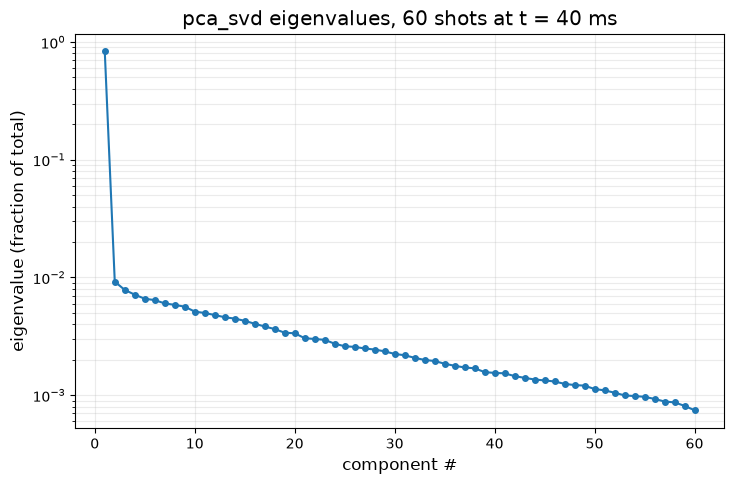

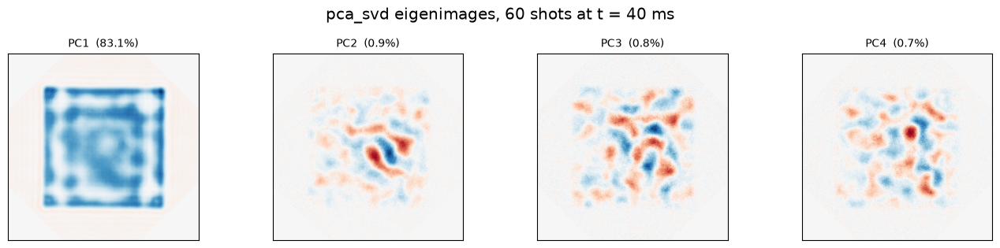

In [9]:
# pca_svd on the full 60-shot t = 40 ms dataset (2026-07-27_40ms/):
# eigenvalue spectrum on log-lin axes, then the leading eigenimages.
PCA60_DIR = os.path.join(SCRIPT_DIR, "2026-07-27_40ms")
N_EIG_SHOW = 4   # leading eigenimages to display

stack60_svd = np.stack([
    rotate(ShotFile(p, cam=CAM, crop_box=CROP_BOX).od,45,reshape=False)
    for p in sorted(glob.glob(os.path.join(PCA60_DIR, "*bec_box2*.h5")))
])
print(f"image stack: {stack60_svd.shape}")

evals60_svd, evecs60_svd = pca_svd(stack60_svd)

# eigenvalue spectrum, log-lin
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.semilogy(np.arange(1, len(evals60_svd) + 1), evals60_svd, "o-", ms=4, color="C0")
ax.set_xlabel("component #")
ax.set_ylabel("eigenvalue (fraction of total)")
ax.set_title(f"pca_svd eigenvalues, {len(stack60_svd)} shots at t = 40 ms")
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()

# table of the leading eigenimages
ncols = 4
nrows = int(np.ceil(N_EIG_SHOW / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.2 * nrows))
for j, ax in enumerate(axes.ravel()):
    if j >= N_EIG_SHOW:
        ax.axis("off")
        continue
    comp = evecs60_svd[..., j]
    lim = np.abs(comp).max()
    ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC{j + 1}  ({evals60_svd[j]:.1%})", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"pca_svd eigenimages, {len(stack60_svd)} shots at t = 40 ms")
fig.tight_layout()
plt.show()


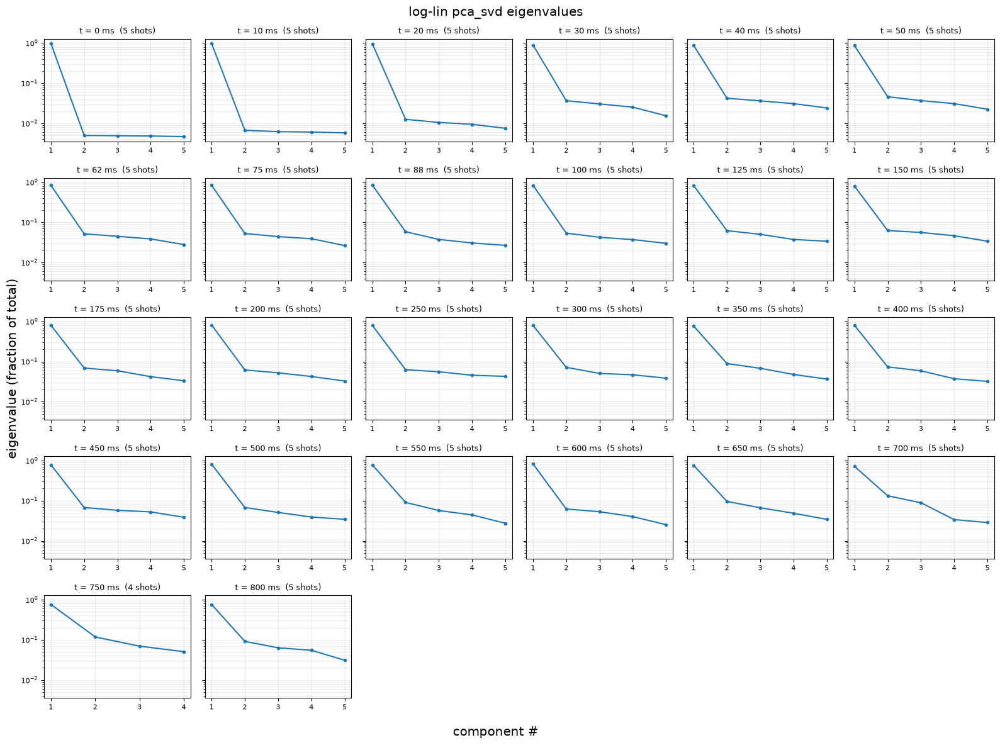

In [10]:
# Per-time PCA over the evolution dataset (~5 shots per time): pca_svd on
# each time's shots ALONE, every eigenvalue spectrum on log-lin axes.
# n shots at a time -> n eigenvalues in that spectrum.
pca_by_time_svd = {_t: pca_svd(stack_svd[t_shots_svd == _t]) for _t in times_svd}

ncols = 6
nrows = int(np.ceil(len(times_svd) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.4 * nrows),
                         sharey=True)
for ax, _t in zip(axes.ravel(), times_svd):
    evals_t, _ = pca_by_time_svd[_t]
    ax.semilogy(np.arange(1, len(evals_t) + 1), evals_t, "o-", ms=3, color="C0")
    ax.set_title(f"t = {_t:g} ms  ({len(evals_t)} shots)", fontsize=9)
    ax.set_xticks(np.arange(1, len(evals_t) + 1))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.25, which="both")
for ax in axes.ravel()[len(times_svd):]:
    ax.axis("off")
fig.supxlabel("component #")
fig.supylabel("eigenvalue (fraction of total)")
fig.suptitle("log-lin pca_svd eigenvalues")
fig.tight_layout()
plt.show()


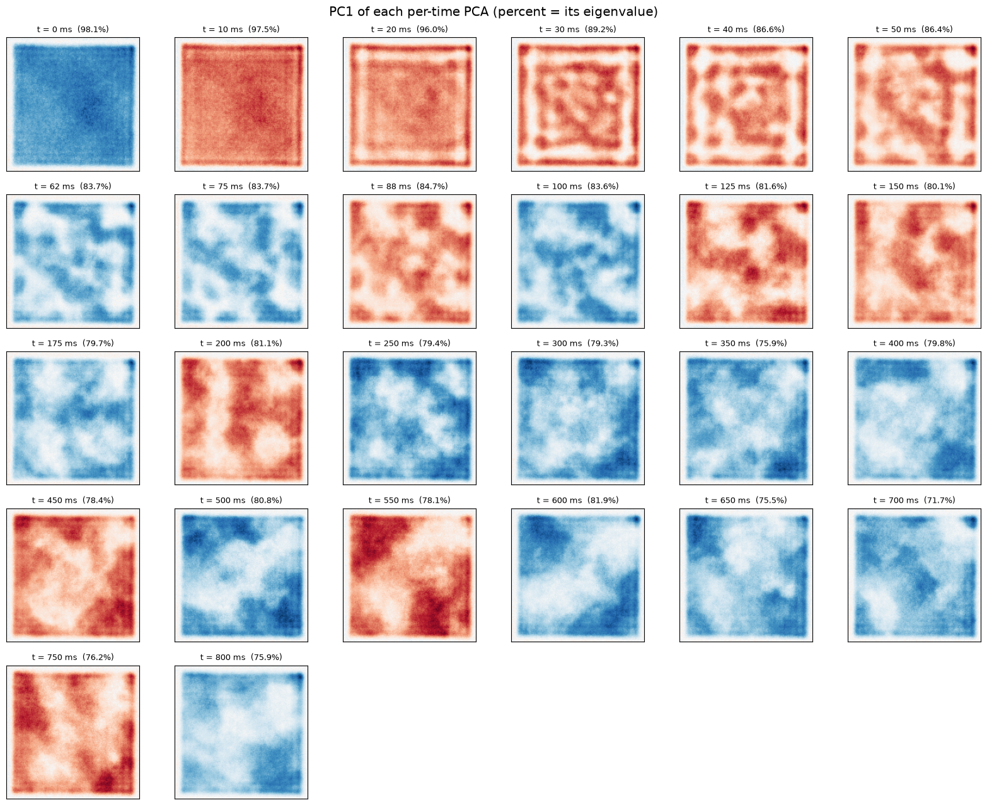

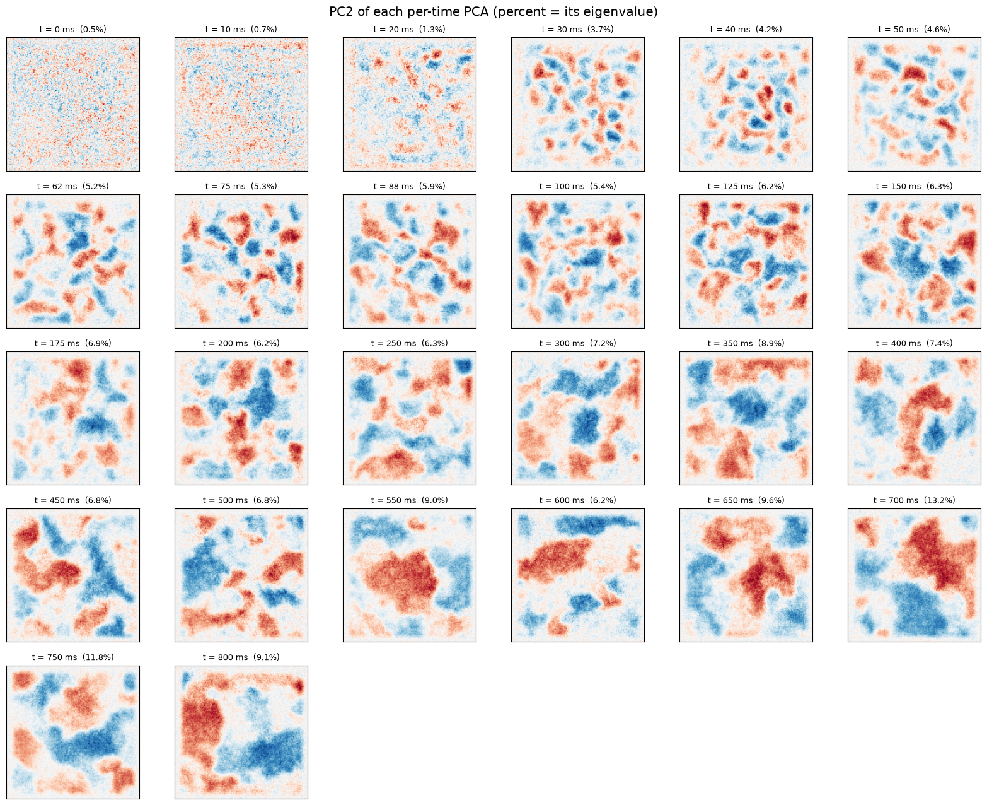

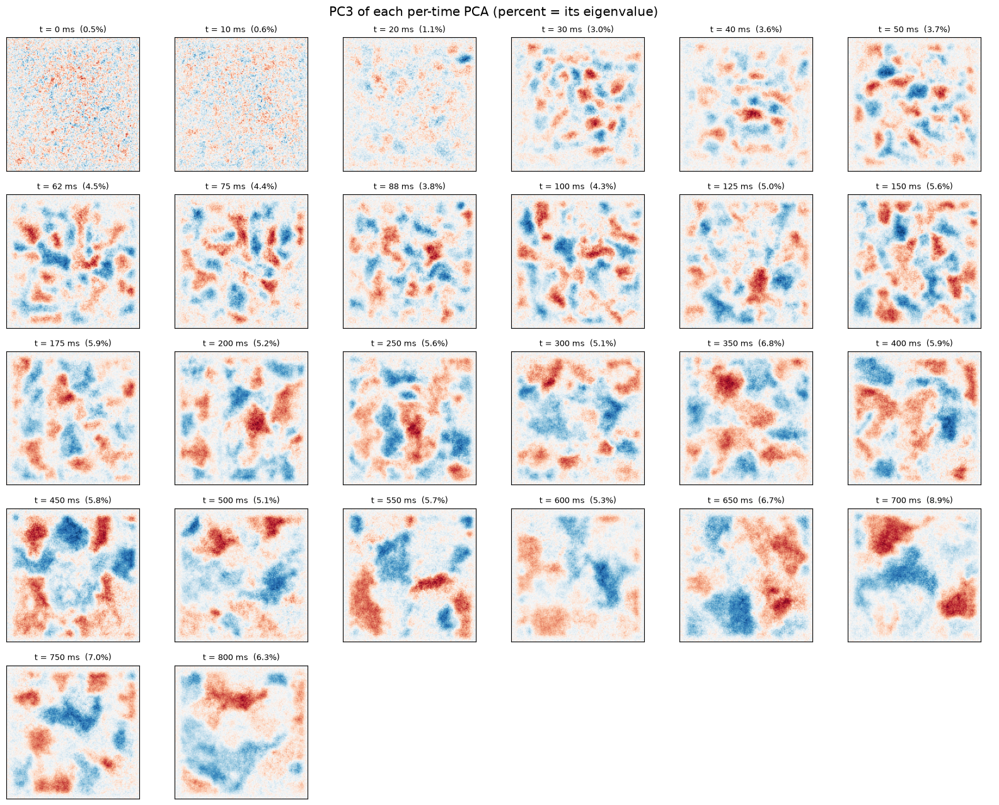

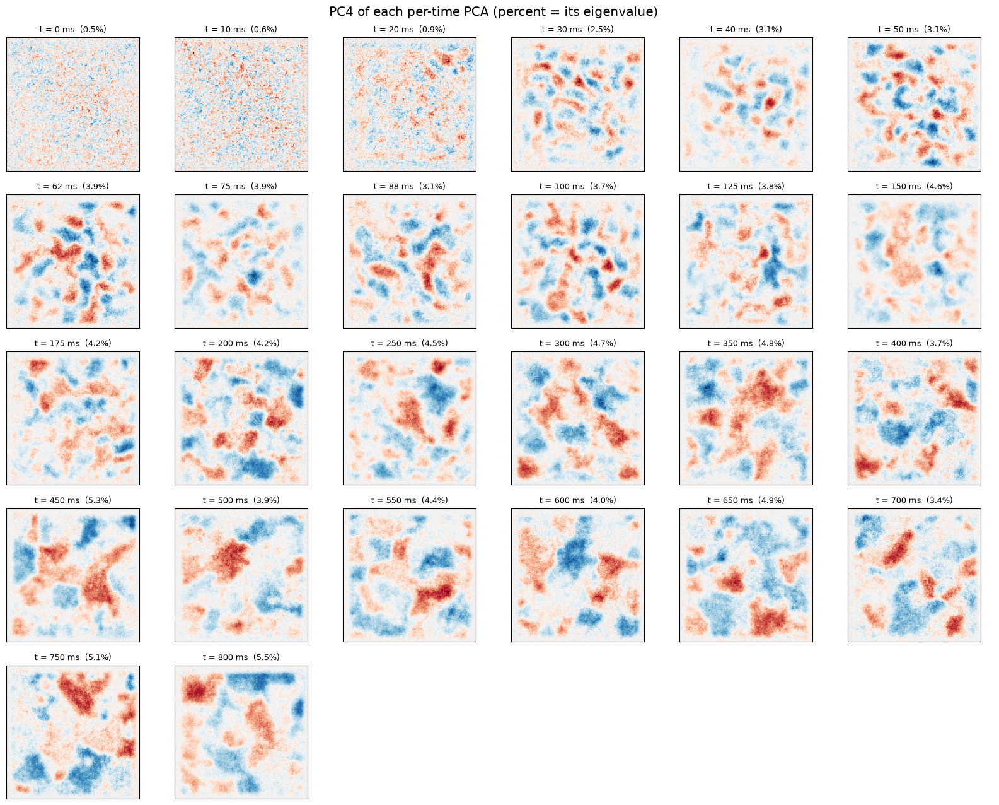

In [11]:
# The k-th eigenvector of each per-time PCA as an image: one table per
# component for PC1..PC4 (reuses pca_by_time_svd from the cell above).
ncols = 6
nrows = int(np.ceil(len(times_svd) / ncols))
for k in range(4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.6 * nrows))
    for ax, _t in zip(axes.ravel(), times_svd):
        evals_t, evecs_t = pca_by_time_svd[_t]
        ax.set_xticks([])
        ax.set_yticks([])
        if k >= evecs_t.shape[-1]:
            ax.axis("off")
            continue
        comp = evecs_t[..., k]
        lim = np.abs(comp).max()
        ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"t = {_t:g} ms  ({evals_t[k]:.1%})", fontsize=9)
    for ax in axes.ravel()[len(times_svd):]:
        ax.axis("off")
    fig.suptitle(f"PC{k + 1} of each per-time PCA (percent = its eigenvalue)")
    fig.tight_layout()
    plt.show()


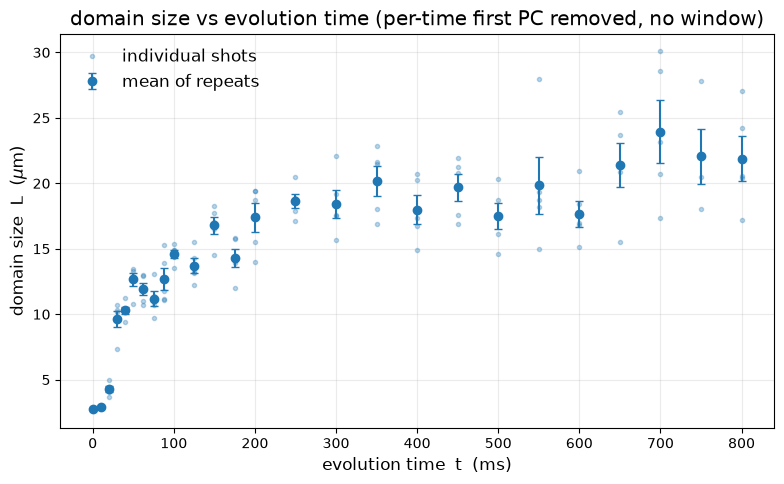

In [12]:
# removes the first principal component of EACH TIME'S OWN PCA, NO window.
# (pcs_svd is the PCA over every shot at every time -- one compromise envelope
# for the whole run; the per-time basis tracks the envelope as it drifts.)
# L = 2 pi <S> / <k S> straight on the cleaned shot.
L_shots_svd1 = np.empty(len(stack_svd))
for _t in times_svd:
    _m = t_shots_svd == _t
    _, _pcs_t = pca_by_time_svd[_t]        # per-time basis built two cells up
    L_shots_svd1[_m] = [_domain_length_raw(remove_pca_components(im, _pcs_t, 1)[0])
                        for im in stack_svd[_m]]
L_shots_svd1 *= 0.696
_tm = np.array(times_svd, float)
L_mean_svd1 = np.array([L_shots_svd1[t_shots_svd == t].mean() for t in times_svd])
L_sem_svd1 = np.array([L_shots_svd1[t_shots_svd == t].std(ddof=1)
                       / np.sqrt((t_shots_svd == t).sum()) for t in times_svd])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots_svd, L_shots_svd1, "o", ms=3, color="C0", alpha=0.3,
        label="individual shots")
ax.errorbar(_tm, L_mean_svd1, yerr=L_sem_svd1, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("domain size vs evolution time (per-time first PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
